In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
import seaborn as sns
import pandas as pd
import pickle as pkl
import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

import scipy.signal as ss
import scipy.io as sio
from scipy.signal import butter, lfilter, hilbert
from scipy import signal
from scipy.signal import freqz
from scipy.signal import butter, lfilter, freqz, find_peaks
from scipy.stats import zscore
from scipy.ndimage import gaussian_filter1d
from scipy.signal import hilbert

def get_envelope(signal):
    return np.abs(hilbert(signal))

def butter_bandpass(lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y




import sys
sys.path.append('/home/diogo/miniforge3/envs/core_neuron/lib/python')
import neuron

In [2]:
def get_population_gids(run, population):

    return np.array([
        gid
        for gid, pop in run['cellType'].items()
        if pop == population
    ], dtype=int)

def population_firing_rate(data,sim_info,population,t_start=0.0,t_end=None):

    if t_end is None:
        t_end = sim_info['simConfig']['duration']

    gids = get_population_gids(sim_info,population)

    mask = ((np.array(data['spkt']) >= t_start) & (np.array(data['spkt']) < t_end) & np.isin(data['spkid'], gids))

    n_spikes = np.sum(mask)

    duration_s = (t_end - t_start) / 1000.0

    return (
        n_spikes /
        len(gids) /
        duration_s
    )


def plot_raster(spkid, spkt, tinitial = 0.0, tfinal = 5.0, transient = 1.0): # seconds
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.transforms import blended_transform_factory


    # ============================================================
    # Global figure style
    # ============================================================

    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],

        'axes.labelsize': 22,
        'xtick.labelsize': 16,
        'ytick.labelsize': 16,

        # Better vector export / Inkscape compatibility
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'svg.fonttype': 'none',

        'axes.linewidth': 0.8,
    })


    # ============================================================
    # Colors
    # ============================================================

    colors = {
        'HL23PYR': '#D55E00',
        'HL23SST': '#0072B2',
        'HL23PV':  '#009E73',
        'HL23VIP': '#CC79A7',
    }


    # ============================================================
    # Population definitions
    # ============================================================

    population_ranges = {
        'HL23PYR': (0, 799),
        'HL23SST': (800, 849),
        'HL23PV':  (850, 919),
        'HL23VIP': (920, 999),
    }

    population_names = {
        'HL23PYR': 'PYR',
        'HL23SST': 'SST',
        'HL23PV': 'PV',
        'HL23VIP': 'VIP',
    }


    # ============================================================
    # Plot interval
    # ============================================================

    # First 1 s discarded
    t_start_ms = transient*1000 # s

    # Show 10 s after the discarded interval
    t_duration_ms = 10000

    t_stop_ms = t_start_ms + t_duration_ms

    xlim_s = (
        tinitial,
        tfinal
    )


    # ============================================================
    # Helper functions
    # ============================================================

    def clean_axis(ax):
        """Remove the normal Matplotlib frame and ticks."""

        for spine in ax.spines.values():
            spine.set_visible(False)

        ax.tick_params(
            left=False,
            bottom=False,
            labelleft=False,
            labelbottom=False
        )


    def relative_time(t):
        """
        Convert absolute simulation time in ms into
        seconds relative to t_start_ms.
        """
        return (np.asarray(t) - t_start_ms) / 1000


    def add_horizontal_scalebar(
        ax,
        length=1.0,
        label='1 s',
        x0=0.0,
        y_axes=-0.035,
        linewidth=1.5
    ):
        """
        Horizontal time scale bar.

        x is in data units (seconds).
        y is in axes coordinates.
        """

        trans = blended_transform_factory(
            ax.transData,
            ax.transAxes
        )

        ax.plot(
            [x0, x0 + length],
            [y_axes, y_axes],
            transform=trans,
            color='black',
            lw=linewidth,
            solid_capstyle='butt',
            clip_on=False
        )

        ax.text(
            x0 + length / 2,
            y_axes - 0.035,
            label,
            transform=trans,
            ha='center',
            va='top',
            fontsize=8,
            clip_on=False
        )


    # ============================================================
    # Spike data
    # ============================================================

    # These are the ONLY data variables required
    spkt = np.asarray(spkt)
    spkid = np.asarray(spkid)


    # ============================================================
    # Spike time mask
    # ============================================================

    spike_mask = (
        (spkt >= t_start_ms) &
        (spkt <= t_stop_ms)
    )


    # ============================================================
    # Select spikes for plotting
    # ============================================================

    spkt_plot = spkt[spike_mask]
    spkid_original = spkid[spike_mask]

    spkid_plot = spkid_original.astype(float).copy()


    # ============================================================
    # Vertical spacing between populations
    # ============================================================

    gap = 15


    # ============================================================
    # Assign colors
    # ============================================================

    spike_colors = np.empty(
        len(spkid_plot),
        dtype=object
    )


    for i, (pop, (gid_min, gid_max)) in enumerate(
        population_ranges.items()
    ):

        mask = (
            (spkid_original >= gid_min) &
            (spkid_original <= gid_max)
        )

        # Shift populations vertically
        spkid_plot[mask] += i * gap

        # Assign population color
        spike_colors[mask] = colors[pop]


    # ============================================================
    # Figure
    # ============================================================

    fig, ax_raster = plt.subplots(
        figsize=(16, 6.0)
    )


    # ============================================================
    # Raster
    # ============================================================

    ax_raster.scatter(
        relative_time(spkt_plot),
        spkid_plot,
        s=3,
        c=spike_colors,
        linewidths=0,

        # Spikes rasterized, labels/lines remain vector
        rasterized=True
    )

    ax_raster.set_xlim(xlim_s)


    # ============================================================
    # Raster population separators
    # ============================================================

    pop_items = list(
        population_ranges.items()
    )


    for i in range(1, len(pop_items)):

        previous_pop, (
            previous_min,
            previous_max
        ) = pop_items[i - 1]

        current_pop, (
            current_min,
            current_max
        ) = pop_items[i]

        previous_top = (
            previous_max +
            (i - 1) * gap
        )

        current_bottom = (
            current_min +
            i * gap
        )

        separator = (
            previous_top +
            current_bottom
        ) / 2

        ax_raster.axhline(
            separator,
            color='0.65',
            lw=0.55,
            zorder=0
        )


    # ============================================================
    # Raster population labels
    # ============================================================

    for i, (pop, (gid_min, gid_max)) in enumerate(
        population_ranges.items()
    ):

        offset = i * gap

        center = (
            (gid_min + gid_max) / 2
            + offset
        )

        ax_raster.text(
            -0.012,
            center,
            population_names[pop],

            transform=ax_raster.get_yaxis_transform(),

            ha='right',
            va='center',

            fontsize=20,

            clip_on=False
        )


    # ============================================================
    # ID label
    # ============================================================

    ax_raster.text(
        -0.055,
        0.5,
        'ID',

        transform=ax_raster.transAxes,

        rotation=90,

        ha='center',
        va='center',

        fontsize=9,

        clip_on=False
    )


    # ============================================================
    # Raster limits
    # ============================================================

    ax_raster.set_ylim(
        spkid_plot.min() - 5,
        spkid_plot.max() + 5
    )

    clean_axis(ax_raster)


    # ============================================================
    # 1-second time scale bar
    # ============================================================

    add_horizontal_scalebar(
        ax_raster,
        length=1,
        label='1 s',

        # Slightly inside left edge
        x0=0.0,

        y_axes=-0.025
    )


    # ============================================================
    # Final spacing
    # ============================================================

    fig.subplots_adjust(
        left=0.105,
        right=0.965,
        top=0.98,
        bottom=0.10
    )


    # ============================================================
    # Save
    # ============================================================

    # fig.savefig(
    #     'Figures/raster_only.pdf',
    #     format='pdf',
    #     dpi=600,
    #     bbox_inches='tight'
    # )

    # fig.savefig(
    #     'Figures/raster_only.svg',
    #     format='svg',
    #     bbox_inches='tight'
    # )

    plt.show()

In [ ]:
def plot_raster_voltage(
    spkid,
    spkt,
    data,
    sim_info,
    tinitial=0.0,
    tfinal=5.0,
    transient=1.0,
    savefig = False, 
    time_scale_bar = 1.0
):
    """
    Plot voltage traces for representative neurons together with
    a population-colored raster plot.

    Parameters
    ----------
    spkid : array-like
        Spike neuron IDs.

    spkt : array-like
        Spike times in ms.

    data : dict
        Simulation data containing:
            data['V_soma']['cell_1']
            data['V_soma']['cell_800']
            data['V_soma']['cell_850']
            data['V_soma']['cell_920']

    sim_info : dict
        Simulation information containing:
            sim_info['simConfig']['duration']
        Duration must be in ms.

    tinitial : float
        Initial plotted time in seconds, relative to the end
        of the transient.

    tfinal : float
        Final plotted time in seconds, relative to the end
        of the transient.

    transient : float
        Initial transient discarded from the plot, in seconds.
    """

    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.transforms import blended_transform_factory


    # ============================================================
    # Global figure style
    # ============================================================

    plt.rcParams.update({
        'font.family': 'serif',
        'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],

        'axes.labelsize': 22,
        'xtick.labelsize': 16,
        'ytick.labelsize': 16,

        # Better vector export / Inkscape compatibility
        'pdf.fonttype': 42,
        'ps.fonttype': 42,
        'svg.fonttype': 'none',

        'axes.linewidth': 0.8,
    })


    # ============================================================
    # Colors
    # ============================================================

    colors = {
        'HL23PYR': '#D55E00',
        'HL23SST': '#0072B2',
        'HL23PV':  '#009E73',
        'HL23VIP': '#CC79A7',
    }


    # ============================================================
    # Population definitions
    # ============================================================

    population_ranges = {
        'HL23PYR': (0, 799),
        'HL23SST': (800, 911),
        'HL23PV':  (912, 1069),
        'HL23VIP': (1070, 1249),
    }

    population_names = {
        'HL23PYR': 'PYR',
        'HL23SST': 'SST',
        'HL23PV':  'PV',
        'HL23VIP': 'VIP',
    }


    # ============================================================
    # Representative cells for voltage traces
    # ============================================================
    trace_gids = {
        'HL23PYR': 1,
        'HL23SST': 800,
        'HL23PV': 912,
        'HL23VIP': 1070,
    }


    # ============================================================
    # Plot interval
    # ============================================================

    transient_ms = transient * 1000.0

    # tinitial/tfinal are relative to the end of the transient
    plot_start_ms = transient_ms + tinitial * 1000.0
    plot_stop_ms  = transient_ms + tfinal * 1000.0

    xlim_s = (
        tinitial,
        tfinal
    )


    # ============================================================
    # Helper functions
    # ============================================================

    def clean_axis(ax):
        """Remove the normal Matplotlib frame and ticks."""

        for spine in ax.spines.values():
            spine.set_visible(False)

        ax.tick_params(
            left=False,
            bottom=False,
            labelleft=False,
            labelbottom=False
        )


    def relative_time(t):
        """
        Convert absolute simulation time in ms into
        seconds relative to the end of the transient.
        """
        return (
            np.asarray(t) - transient_ms
        ) / 1000.0


    def add_vertical_scalebar(
        ax,
        height,
        label,
        x_fraction=-0.012,
        y_fraction=0.15,
        linewidth=1.4,
        text_offset=0.012
    ):
        """
        Vertical scale bar.
        """

        ymin, ymax = ax.get_ylim()
        yrange = ymax - ymin

        y0 = ymin + y_fraction * yrange
        y1 = y0 + height

        xmin, xmax = ax.get_xlim()
        xrange = xmax - xmin

        x = xmin + x_fraction * xrange

        ax.plot(
            [x, x],
            [y0, y1],
            color='black',
            lw=linewidth,
            solid_capstyle='butt',
            clip_on=False
        )

        ax.text(
            x - text_offset * xrange,
            (y0 + y1) / 2,
            label,
            ha='right',
            va='center',
            rotation=90,
            fontsize=8,
            clip_on=False
        )


    def add_horizontal_scalebar(
        ax,
        length=1.0,
        label='1 s',
        x0=0.0,
        y_axes=-0.035,
        linewidth=1.5
    ):
        """
        Horizontal time scale bar.
        """

        trans = blended_transform_factory(
            ax.transData,
            ax.transAxes
        )

        ax.plot(
            [x0, x0 + length],
            [y_axes, y_axes],
            transform=trans,
            color='black',
            lw=linewidth,
            solid_capstyle='butt',
            clip_on=False
        )

        ax.text(
            x0 + length / 2,
            y_axes - 0.035,
            label,
            transform=trans,
            ha='center',
            va='top',
            fontsize=8,
            clip_on=False
        )


    # ============================================================
    # Convert data to arrays
    # ============================================================

    spkt = np.asarray(spkt)
    spkid = np.asarray(spkid)


    # ============================================================
    # Time vectors
    # ============================================================

    duration_ms = sim_info['simConfig']['duration']

    time_voltage = np.linspace(
        0,
        duration_ms,
        len(data['V_soma']['cell_1'])
    )


    # ============================================================
    # Time masks
    # ============================================================

    spike_mask = (
        (spkt >= plot_start_ms) &
        (spkt <= plot_stop_ms)
    )

    voltage_mask = (
        (time_voltage >= plot_start_ms) &
        (time_voltage <= plot_stop_ms)
    )


    # ============================================================
    # Raster data
    # ============================================================

    spkt_plot = spkt[spike_mask]
    spkid_original = spkid[spike_mask]

    spkid_plot = spkid_original.astype(float).copy()


    # Vertical gap between populations
    gap = 15


    # ============================================================
    # Raster colors
    # ============================================================

    spike_colors = np.empty(
        len(spkid_plot),
        dtype=object
    )


    for i, (pop, (gid_min, gid_max)) in enumerate(
        population_ranges.items()
    ):

        mask = (
            (spkid_original >= gid_min) &
            (spkid_original <= gid_max)
        )

        # Shift populations vertically
        spkid_plot[mask] += i * gap

        # Assign population color
        spike_colors[mask] = colors[pop]


    # ============================================================
    # Figure
    # ============================================================

    fig = plt.figure(
        figsize=(12, 8)
    )

    gs = fig.add_gridspec(
        nrows=5,
        ncols=1,

        # 4 voltage traces + raster
        height_ratios=[
            0.42,
            0.42,
            0.42,
            0.42,
            2.3
        ],

        hspace=0.05
    )


    # ============================================================
    # Axes
    # ============================================================

    ax_vip = fig.add_subplot(gs[0])
    ax_pv  = fig.add_subplot(gs[1], sharex=ax_vip)
    ax_sst = fig.add_subplot(gs[2], sharex=ax_vip)
    ax_pyr = fig.add_subplot(gs[3], sharex=ax_vip)
    ax_raster = fig.add_subplot(gs[4], sharex=ax_vip)


    trace_axes = {
        'HL23VIP': ax_vip,
        'HL23PV': ax_pv,
        'HL23SST': ax_sst,
        'HL23PYR': ax_pyr,
    }


    # ============================================================
    # Voltage traces
    # ============================================================

    trace_order = [
        'HL23VIP',
        'HL23PV',
        'HL23SST',
        'HL23PYR'
    ]


    for pop in trace_order:

        ax = trace_axes[pop]

        gid = trace_gids[pop]

        voltage = np.asarray(
            data['V_soma'][f'cell_{gid}']
        )


        ax.plot(
            relative_time(
                time_voltage[voltage_mask]
            ),
            voltage[voltage_mask],

            color=colors[pop],
            lw=2
        )


        ax.set_xlim(xlim_s)

        # Same voltage scale for every cell
        ax.set_ylim(-100, 50)

        clean_axis(ax)


        # Population name on right
        ax.text(
            1.005,
            0.5,
            population_names[pop],

            transform=ax.transAxes,

            color=colors[pop],

            ha='left',
            va='center',

            fontsize=24,

            clip_on=False
        )


    # ============================================================
    # Voltage scale bar
    # ============================================================

    add_vertical_scalebar(
        ax_pyr,
        height=100,
        label='100 mV',
        x_fraction=-0.012,
        y_fraction=0.12
    )


    # ============================================================
    # Raster
    # ============================================================

    ax_raster.scatter(
        relative_time(spkt_plot),
        spkid_plot,

        s=4,
        c=spike_colors,
        linewidths=0,

        # Keep spikes rasterized for smaller PDF/SVG
        rasterized=True
    )

    ax_raster.set_xlim(xlim_s)


    # ============================================================
    # Raster population separators
    # ============================================================

    pop_items = list(
        population_ranges.items()
    )


    for i in range(1, len(pop_items)):

        previous_pop, (
            previous_min,
            previous_max
        ) = pop_items[i - 1]

        current_pop, (
            current_min,
            current_max
        ) = pop_items[i]

        previous_top = (
            previous_max +
            (i - 1) * gap
        )

        current_bottom = (
            current_min +
            i * gap
        )

        separator = (
            previous_top +
            current_bottom
        ) / 2


        ax_raster.axhline(
            separator,
            color='0.65',
            lw=0.55,
            zorder=0
        )


    # ============================================================
    # Raster population labels
    # ============================================================

    for i, (pop, (gid_min, gid_max)) in enumerate(
        population_ranges.items()
    ):

        offset = i * gap

        center = (
            (gid_min + gid_max) / 2
            + offset
        )


        ax_raster.text(
            -0.012,
            center,

            population_names[pop],

            transform=ax_raster.get_yaxis_transform(),

            ha='right',
            va='center',

            fontsize=20,

            clip_on=False
        )


    # ============================================================
    # ID label
    # ============================================================

    ax_raster.text(
        -0.055,
        0.5,
        'ID',

        transform=ax_raster.transAxes,

        rotation=90,

        ha='center',
        va='center',

        fontsize=9,

        clip_on=False
    )


    # ============================================================
    # Raster limits
    # ============================================================

    if len(spkid_plot) > 0:

        ax_raster.set_ylim(
            spkid_plot.min() - 5,
            spkid_plot.max() + 5
        )

    else:

        # Fallback in case no spikes fall inside the interval
        max_gid = max(
            gid_max + i * gap
            for i, (_, (_, gid_max)) in enumerate(
                population_ranges.items()
            )
        )

        ax_raster.set_ylim(
            -5,
            max_gid + 5
        )


    clean_axis(ax_raster)


    # ============================================================
    # 1-second time scale bar
    # ============================================================
    time_scale_bar # s
    add_horizontal_scalebar(
        ax_raster,
        length=time_scale_bar, #s
        label=f'{time_scale_bar} s',
        x0=tinitial,
        y_axes=-0.025
    )


    # ============================================================
    # Final spacing
    # ============================================================

    fig.subplots_adjust(
        left=0.105,
        right=0.965,
        top=0.98,
        bottom=0.075
    )


    # ============================================================
    # Return
    # ============================================================
    if savefig:
        plt.savefig('VoltageTraces_raster.pdf')
    return fig, {
        'VIP': ax_vip,
        'PV': ax_pv,
        'SST': ax_sst,
        'PYR': ax_pyr,
        'raster': ax_raster
    }

In [4]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

def _make_spike_dict(spkt, spkid, gids):
    """
    Convert NetPyNE spkt/spkid arrays into

        spikes[gid] = np.array([t1, t2, t3, ...])

    Spike times are in ms.
    """

    spkt = np.asarray(spkt, dtype=float)
    spkid = np.asarray(spkid, dtype=int)

    gid_set = set(int(gid) for gid in gids)

    spikes = {
        int(gid): []
        for gid in gids
    }

    for t, gid in zip(spkt, spkid):
        gid = int(gid)

        if gid in gid_set:
            spikes[gid].append(float(t))

    for gid in spikes:
        spikes[gid] = np.asarray(
            spikes[gid],
            dtype=float
        )

    return spikes

def compute_spike_stats(
    spkt,
    spkid,
    gids,
    transient=0.0,
    tstop=None,
    min_spikes_cv=3,
):
    """Summarize per-neuron firing rates and ISI CVs for one neuron group.

    Analysis interval: transient < spike_time <= tstop (times in ms).
    Rate: number of spikes in the interval / interval duration in seconds.
    CV: std(ISIs) / mean(ISIs) computed for each neuron separately.

    Silent neurons contribute 0 Hz to firing-rate statistics. A neuron with
    fewer than ``min_spikes_cv`` spikes has undefined CV (NaN); its CV is not
    included in the group CV statistics.

    The standard deviations of both ISIs and cell-level population metrics
    use ddof=0 (population SD).
    """
    if tstop is None or tstop <= transient:
        raise ValueError("tstop must be specified and greater than transient")
    if min_spikes_cv < 3:
        raise ValueError("min_spikes_cv must be at least 3 (two ISIs)")

    gids = np.asarray(list(gids), dtype=int)
    if len(np.unique(gids)) != len(gids):
        raise ValueError("gids contains duplicate neuron IDs")
    if len(spkt) != len(spkid):
        raise ValueError("spkt and spkid must have equal lengths")

    spikes = _make_spike_dict(spkt, spkid, gids)
    duration_s = (float(tstop) - float(transient)) / 1000.0

    rates = np.zeros(len(gids), dtype=float)
    cvs = np.full(len(gids), np.nan, dtype=float)
    n_spikes = np.zeros(len(gids), dtype=int)

    for i, gid in enumerate(gids):
        times = spikes[int(gid)]
        times = np.sort(times[(times > transient) & (times <= tstop)])

        n_spikes[i] = len(times)
        rates[i] = len(times) / duration_s

        if len(times) >= min_spikes_cv:
            isis = np.diff(times)
            if np.all(isis > 0):
                cvs[i] = float(np.std(isis, ddof=0) / np.mean(isis))

    valid_cv = cvs[np.isfinite(cvs)]

    def describe(values):
        if len(values) == 0:
            return float('nan'), float('nan'), float('nan')
        return (
            float(np.mean(values)),
            float(np.median(values)),
            float(np.std(values, ddof=0)),
        )

    rate_mean, rate_median, rate_std = describe(rates)
    cv_mean, cv_median, cv_std = describe(valid_cv)

    return {
        'rateMeanHz': rate_mean,
        'rateMedianHz': rate_median,
        'rateStdHz': rate_std,
        'CVMean': cv_mean,
        'CVMedian': cv_median,
        'CVStd': cv_std,
        'CV': cv_mean,  # compatibility: old ['CV'] is now the mean of cell CVs
        'nCells': int(len(gids)),
        'nSpikingCells': int(np.count_nonzero(n_spikes)),
        'nCVCells': int(len(valid_cv)),
        # One-to-one per-neuron arrays (all have the same ordering):
        'gids': gids,
        'rateHzPerNeuron': rates,
        'CVperNeuron': cvs,
        'nSpikesPerNeuron': n_spikes,
    }

def compute_network_spike_stats(
    spkt,
    spkid,
    pop_gids,
    transient=0.0,
    tstop=None,
    min_spikes_cv=3,
):
    """Report per-neuron firing rate/CV summaries for network populations."""
    populations = {
        pop: list(gids)
        for pop, gids in pop_gids.items()
    }

    all_gids = [gid for gids in populations.values() for gid in gids]
    exc = list(populations.get('HL23PYR', []))
    inh = [
        gid
        for pop in ('HL23SST', 'HL23PV', 'HL23VIP')
        for gid in populations.get(pop, [])
    ]

    if len(set(all_gids)) != len(all_gids):
        raise ValueError('Neuron GIDs overlap between populations')

    groups = {'all': all_gids, 'exc': exc, 'inh': inh}
    groups.update(populations)

    return {
        group: compute_spike_stats(
            spkt=spkt,
            spkid=spkid,
            gids=gids,
            transient=transient,
            tstop=tstop,
            min_spikes_cv=min_spikes_cv,
        )
        for group, gids in groups.items()
    }

# Multiple seeds seeds

In [ ]:
CV = {pop:[] for pop in ['HL23PYR', 'HL23SST', 'HL23PV', 'HL23VIP']}
R = {pop:[] for pop in ['HL23PYR', 'HL23SST', 'HL23PV', 'HL23VIP']}
F = {pop:[] for pop in ['HL23PYR', 'HL23SST', 'HL23PV', 'HL23VIP']}

for k in range(0,10):
    with open(f'../data/DifferentSeeds_CoreNEURON_GPU/DifferentSeeds_CoreNEURON_GPU_{k}_data.pkl', 'rb') as file:
        sim_info = pkl.load(file)

    data = sim_info['simData'].copy()
    sim_info.pop('simData', None)
    cfg = sim_info['simConfig']


    for pop in cfg['allpops']:
        CV[pop].append(data['CV'][pop]['CV'])
        R[pop].append(data['Kuramoto'][pop]['Rmean'])
        F[pop].append(data['popRates'][pop])


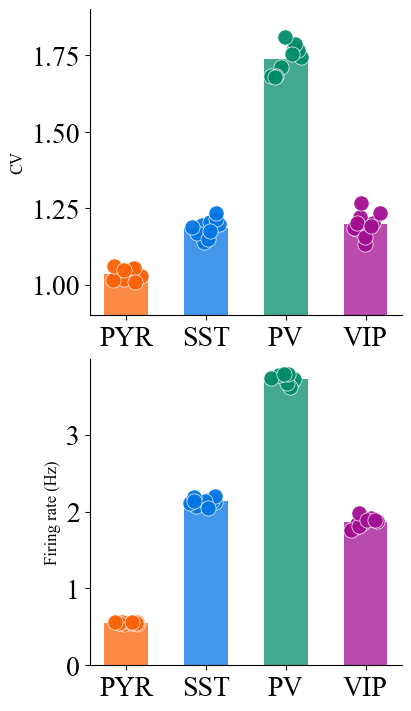

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Polygon

populations = ['HL23PYR', 'HL23SST', 'HL23PV', 'HL23VIP']

type_colors = {
    'HL23PYR': '#fb6106',
    'HL23VIP': '#a10e91',
    'HL23PV':  '#038b69',
    'HL23SST': '#0375e3',
}

metrics = {
    'CV': CV,
    'Kuramoto R': R,
    'Firing rate (Hz)': F,
}

plt.rcParams.update({
    'font.size': 26,          # default font size
    'axes.labelsize': 20,     # x/y axis labels
    'xtick.labelsize': 20,    # x tick labels
    'ytick.labelsize': 20,    # y tick labels
})

populations = cfg['allpops']

fig, axes = plt.subplots(len(metrics),1, figsize=(4.0, 7.0),constrained_layout=True)

# If there is only one metric, make axes iterable
if len(metrics) == 1:
    axes = [axes]

rng = np.random.default_rng(42)

for ax, (metric_name, metric_data) in zip(axes, metrics.items()):

    means = np.array([
        np.mean(metric_data[pop])
        for pop in populations
    ])

    stds = np.array([
        np.std(metric_data[pop], ddof=1)
        for pop in populations
    ])

    x = np.arange(len(populations))

    # -----------------------------
    # Bars
    # -----------------------------
    bars = ax.bar(
        x,
        means,
        #yerr=stds,
        capsize=2.5,
        width=0.55,
        alpha=0.75,
        zorder=1
    )

    # Population colors
    for bar, pop in zip(bars, populations):
        bar.set_facecolor(type_colors[pop])
        bar.set_edgecolor('none')

    # -----------------------------
    # Individual seeds
    # -----------------------------
    for i, pop in enumerate(populations):

        values = np.asarray(metric_data[pop])

        # Small horizontal jitter
        jitter = rng.uniform(
            -0.20,
            0.20,
            size=len(values)
        )

        ax.scatter(
            x[i] + jitter,
            values,
            s=120,                 
            color=type_colors[pop],
            edgecolor='white',
            linewidth=0.5,
            alpha=0.95,
            zorder=3
        )

    # -----------------------------
    # Formatting
    # -----------------------------
    ax.set_ylabel(metric_name)

    ax.set_xticks(x)

    # Only show population labels on bottom panel
    #if ax is not axes[-1]:
    #ax.tick_params(axis='x',which='both',bottom=False,labelbottom=False)
    #else:
    ax.set_xticklabels(['PYR', 'SST', 'PV', 'VIP'] )



    # Remove top/right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


    ax.yaxis.label.set_size(12)


# Example limits
for ax, (metric_name, _) in zip(axes, metrics.items()):

    if metric_name == 'CV':
        ax.set_ylim(0.9, None)

    # Add other metric-specific limits if desired:
    # if metric_name == 'Firing rate (Hz)':
    #     ax.set_ylim(0, 4)


sns.despine()

plt.savefig(
    'CV_R_F_seed.svg',
    bbox_inches='tight'
)

plt.show()

# EEG

In [ ]:
folder = 'BASELINE_CoreNEURON'
with open(f'../data/{folder}/{folder}_data.pkl', 'rb') as file:
    sim_info = pkl.load(file)

data = sim_info['simData'].copy()
sim_info.pop('simData', None)
cfg = sim_info['simConfig']

spkt = data['spkt']
spkid = data['spkid']

(<Figure size 1200x800 with 5 Axes>,
 {'VIP': <Axes: >,
  'PV': <Axes: >,
  'SST': <Axes: >,
  'PYR': <Axes: >,
  'raster': <Axes: >})

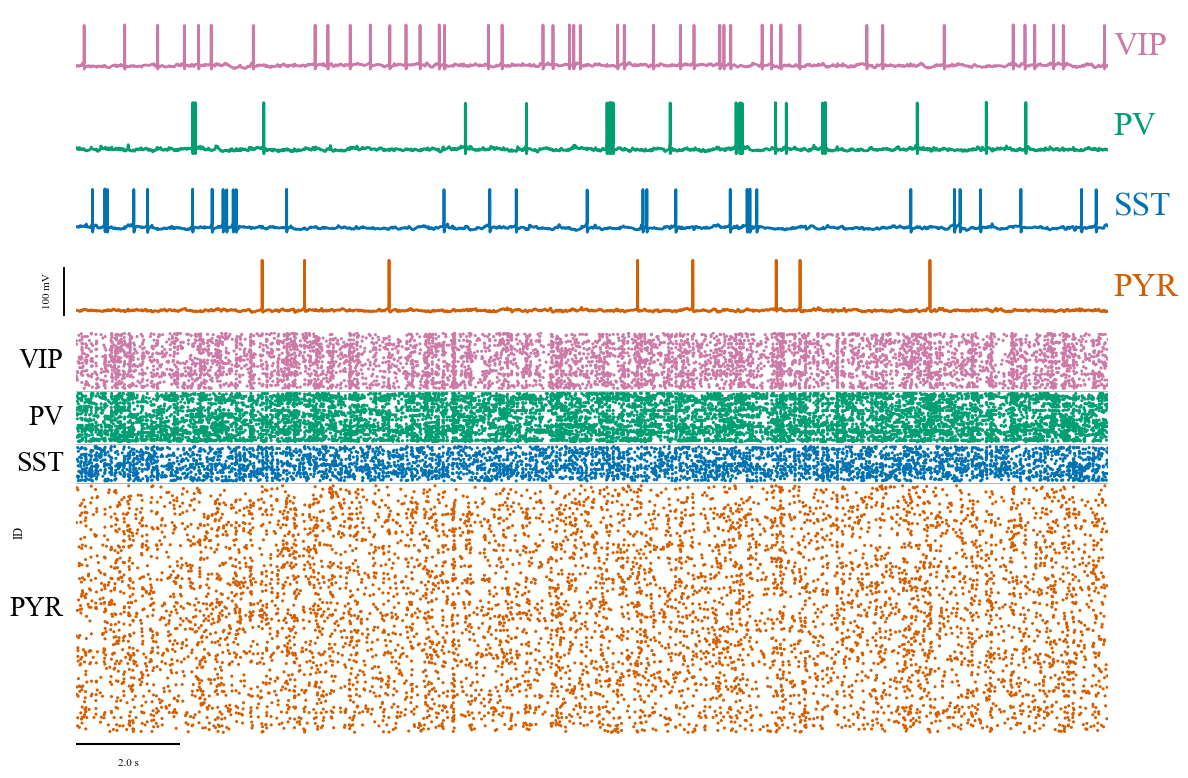

In [30]:
plot_raster_voltage(spkid,spkt,data,sim_info,tinitial=0.0,tfinal=20.0,transient=1.0,savefig=False, time_scale_bar=2.0)

In [46]:
import numpy as np
from lfpykit.eegmegcalc import NYHeadModel

# ============================================================
# 1. NetPyNE current dipole
# ============================================================

P = np.asarray(data['dipoleSum'],dtype=float)

assert P.ndim == 2
assert P.shape[1] == 3

record_step = cfg['recordDipoleStep']
duration = cfg['duration']

time = np.arange(P.shape[0]) * record_step

# LFPykit wants:
# 3 x time
p_model = P.T


# ============================================================
# 2. Load New York Head
# ============================================================

nyhead = NYHeadModel()


# ============================================================
# 3. Choose anatomical source location
# ============================================================

target_mni = np.array([-53, 2, -30])


vertex_idx = nyhead.return_closest_idx(target_mni)

source_vertex = (nyhead.cortex[:, vertex_idx].copy())

source_error = np.linalg.norm(source_vertex - target_mni)

print("Requested MNI position:",target_mni)

print("NYHead cortical vertex:",source_vertex)

print("distance from target:",source_error,"mm")

nyhead.set_dipole_pos(source_vertex)


# ============================================================
# 4. Rotate YOUR coordinate system into the head
# ============================================================

model_surface_axis = np.array([0.0,1.0,0.0])


p_head = nyhead.rotate_dipole_to_surface_normal(p_model,orig_ax_vec=model_surface_axis.copy())


# ============================================================
# 5. EEG forward model
# ============================================================

M_head = (nyhead.get_transformation_matrix())

print("Head transformation:",M_head.shape)

# 231 electrodes x time
eeg_mV = M_head @ p_head

# Convert to the conventional EEG unit
eeg_uV = eeg_mV * 1000.0


print(
    "EEG shape:",
    eeg_uV.shape
)

print(
    "EEG min/max (uV):",
    eeg_uV.min(),
    eeg_uV.max()
)

Requested MNI position: [-53   2 -30]
NYHead cortical vertex: [-51.62047338   3.30774641 -28.52452958]
distance from target: 2.40630574261284 mm
Head transformation: (231, 3)
EEG shape: (231, 210000)
EEG min/max (uV): -0.008588570244650175 0.004804480906329314


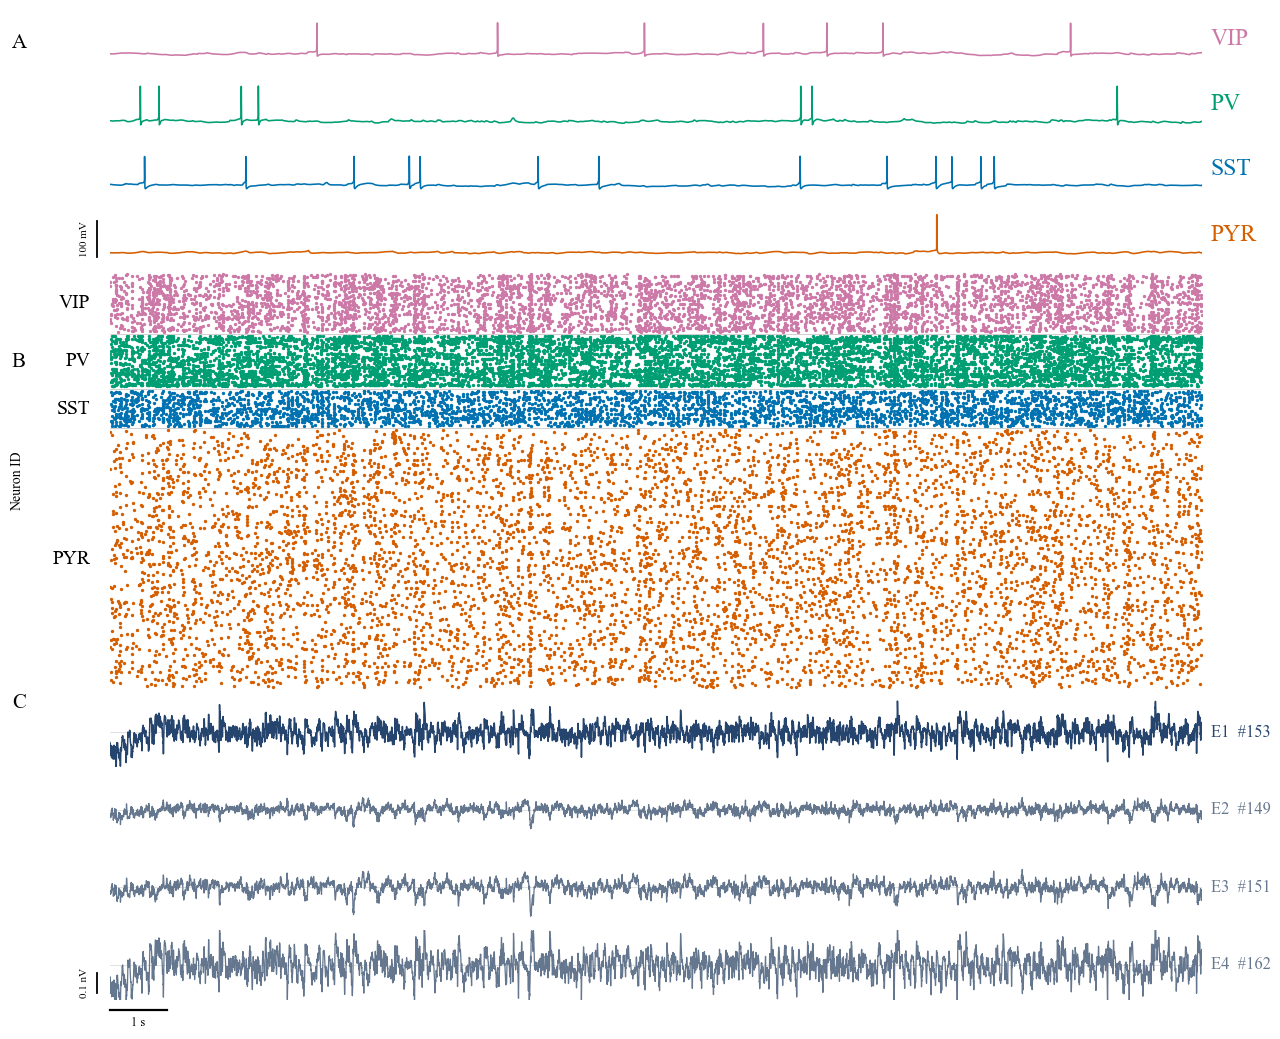

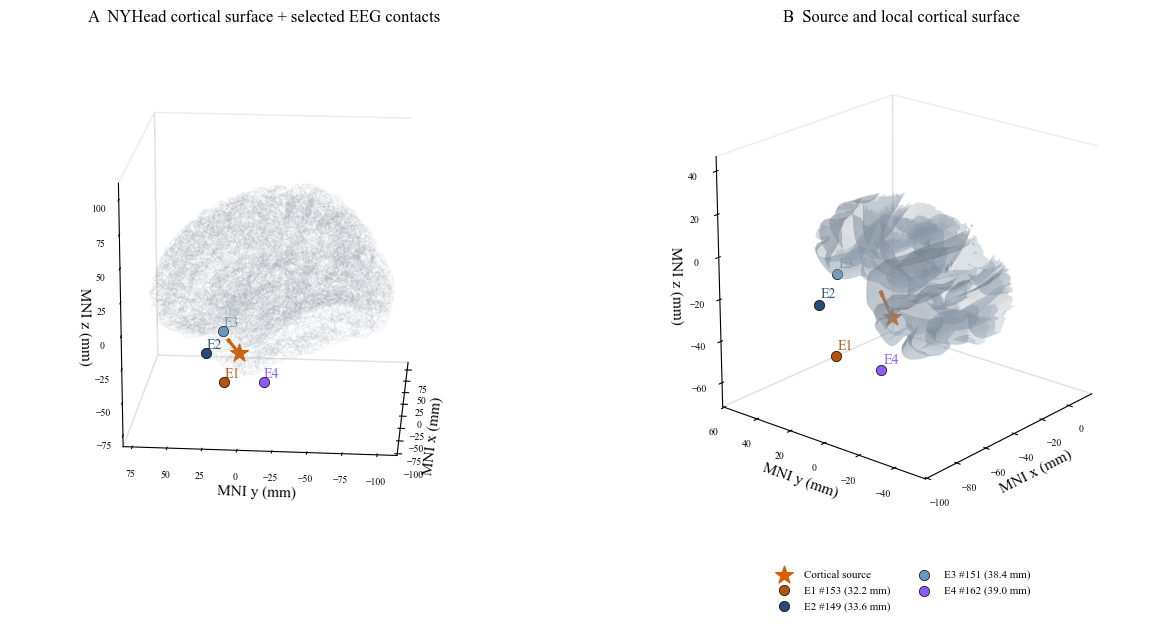

In [49]:
import importlib

import l23_eeg_figure_helpers as h_eeg

importlib.reload(l23_eeg_figure_helpers)

plot_network_eeg_panel = (
    l23_eeg_figure_helpers.plot_network_eeg_panel
)

# Find the actual four closest electrodes
electrode_ids, distances_mm, gains = h_eeg.select_electrodes(
    nyhead, n=4, method="distance"
)

# Compute only those four EEG channels
eeg_4, eeg_time_ms = h_eeg.construct_eeg(
    data, cfg, nyhead,
    electrode_ids=electrode_ids,
    model_surface_axis=(0, 1, 0)
)

# Figure 1: voltage, raster, EEG
fig1, axes1 = plot_network_eeg_panel(
    data, cfg, eeg_4, eeg_time_ms,
    electrode_ids,
    transient_s=1.0,
    start_s=0.0,
    stop_s=19.0
)

# Figure 2: anatomical source and electrodes
fig2, axes2 = h_eeg.plot_nyhead_source_electrodes(
    nyhead,
    electrode_ids,
    distances_mm,
    target_mni=target_mni
)
